# Задание 4.13

В корзину с $n$ шарами опускают белый шар. Найдите вероятность того, что извлечённый шар окажется белым, если первоначальное распределение белых шаров в корзине имеет биномиальное распределение с параметром $p$. Решите задачу для общего случая и для конкретных $n=10$, $p=\frac13$.

**Ответ (в листке):** $0{,}15625$.

*Общее требование листка:* ко всем задачам, где есть числовой ответ, напишите программу (код) с использованием инструментария **Jupyter Notebook**, который иллюстрирует график зависимости относительной частоты $\hat p(A)\overset{\text{def}}{=}\dfrac{N(A)}{N}$ события $A$ от числа проведённых реализаций опыта $N$.

## Теория

**Модель.** Пусть $X$ — первоначальное число белых шаров, $X\sim\mathrm{Bin}(n,p)$:

$$
\mathbb P(X=k)=C_n^k p^k(1-p)^{n-k},\qquad k=0,1,\dots,n .
$$

Гипотезы $H_k=\{X=k\}$ образуют полную группу. После добавления белого шара в корзине $n+1$ шар, из них $k+1$ белый, поэтому $\mathbb P(\text{белый}\mid H_k)=\dfrac{k+1}{n+1}$.

**Формула полной вероятности:**

$$
\mathbb P(A)=\sum_{k=0}^{n}\mathbb P(H_k)\,\frac{k+1}{n+1}=\frac{\mathbb E X+1}{n+1}=\frac{np+1}{n+1}.
$$

**Для $n=10$, $p=\frac13$:**

$$
\mathbb P(A)=\frac{10/3+1}{11}=\frac{13}{33}\approx0{,}393939 .
$$

**Замечание об ответе в листке.** Число $0{,}15625=\frac{5}{32}$ не получается из условия ни по этой формуле, ни при других разумных прочтениях. Например, если считать все составы корзины равновозможными, получится $\frac{n+2}{2(n+1)}=\frac{6}{11}$. Зато $\frac{5}{32}$ — это в точности $P_3=3q^2-2q^3$ при $q=\frac14$ из задачи 4.11, так что ответ, скорее всего, попал сюда от другой задачи. Моделирование ниже подтверждает значение $\frac{13}{33}$.

Σ P(H_k)·(k+1)/(n+1) = 13/33 = 0.393939;   (np+1)/(n+1) = 13/33


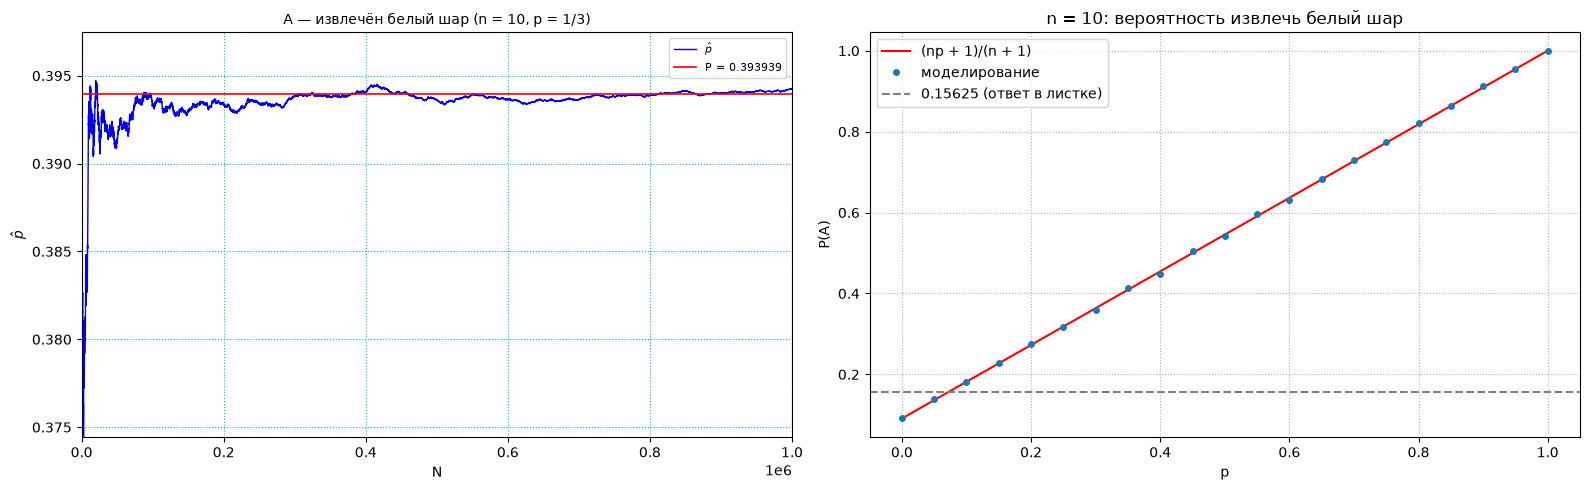

p̂(A) = 0.394263 при N = 1000000;  P(A) = 13/33 = 0.393939


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from math import comb

rng = np.random.default_rng(2026)

def plot_freq(ax, hits, p, title, cond=None, skip=None):
    """График относительной частоты p̂ = N(A)/N от числа опытов N (красная линия — точная вероятность p).
    Если задано cond — строится условная частота N(A∩B)/N(B)."""
    hits = np.asarray(hits, dtype=bool)
    n = np.arange(1, hits.size + 1)
    if cond is None:
        freq = np.cumsum(hits) / n                                   # p̂(A) после каждого опыта
    else:
        nb = np.cumsum(cond)
        freq = np.where(nb > 0, np.cumsum(hits & cond) / np.maximum(nb, 1), np.nan)  # p̂(A|B)
    step = max(1, hits.size // 20000)                                # прореживаем точки для отрисовки
    ax.plot(n[::step], freq[::step], color="blue", lw=1, label=r"$\hat p$")
    ax.axhline(p, color="red", lw=1.2, label=f"P = {p:.6f}")
    skip = skip or max(50, hits.size // 300)                         # первые опыты — сильный разброс
    lo, hi = np.nanmin(freq[skip:]), np.nanmax(freq[skip:])
    lo, hi = min(lo, p), max(hi, p)
    pad = 0.15 * (hi - lo) + 1e-12
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, hits.size)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("N")
    ax.set_ylabel(r"$\hat p$")
    ax.grid(ls=":", color="c")
    ax.legend(fontsize=8, loc="upper right")
    return freq[-1]


# ---------- Точная вероятность: формула полной вероятности ----------
n, p = 10, Fraction(1, 3)
P_total = sum(comb(n, k) * p**k * (1 - p)**(n - k) * Fraction(k + 1, n + 1) for k in range(n + 1))
print(f"Σ P(H_k)·(k+1)/(n+1) = {P_total} = {float(P_total):.6f};   (np+1)/(n+1) = {(n*p + 1)/(n + 1)}")

# ---------- Моделирование ----------
N = 1_000_000
X = rng.binomial(n, float(p), N)            # первоначальное число белых шаров
ball = rng.integers(0, n + 1, N)            # номер извлечённого шара; шары 0..X — белые (X исходных + добавленный)
hits = ball <= X                            # извлечён белый шар

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
ph = plot_freq(axes[0], hits, float(P_total), "A — извлечён белый шар (n = 10, p = 1/3)")

# зависимость от p: формула (np+1)/(n+1) и моделирование
ps = np.linspace(0, 1, 21)
axes[1].plot(ps, (n*ps + 1)/(n + 1), "r", label="(np + 1)/(n + 1)")
axes[1].plot(ps, [(rng.integers(0, n + 1, 20_000) <= rng.binomial(n, pv, 20_000)).mean() for pv in ps],
             "o", ms=4, label="моделирование")
axes[1].axhline(0.15625, color="gray", ls="--", label="0.15625 (ответ в листке)")
axes[1].set_xlabel("p"); axes[1].set_ylabel("P(A)"); axes[1].grid(ls=":"); axes[1].legend()
axes[1].set_title("n = 10: вероятность извлечь белый шар")
fig.tight_layout()
plt.show()

print(f"p̂(A) = {ph:.6f} при N = {N};  P(A) = 13/33 = {13/33:.6f}")